In [5]:
import chromadb
import os
import uuid
from chromadb.utils.embedding_functions import OpenCLIPEmbeddingFunction #for image embedding
from chromadb.utils.data_loaders import ImageLoader

In [2]:
#------------Configs---------------
PERSIST_DIR = "./chroma_multimodal_local_dataloader"
COLLECTION_NAME = "pets_local_dataloader"

DOG_IMAGES = ["images/dog1.jpg", "images/dog2.jpg", "images/dog3.jpg"]
CAT_IMAGES = ["images/cat1.jpg", "images/cat2.jpg", "images/cat3.jpg"]

In [3]:
# Step 1 - เตรียม path ของรูปและ metadata
all_image_paths = DOG_IMAGES + CAT_IMAGES
labels = ["dog"] * len(DOG_IMAGES) + ["cat"] * len(CAT_IMAGES)
doc_ids = [str(uuid.uuid4()) for _ in all_image_paths]
docs_descripttion = [f"A photo of a {lbl}" for lbl in labels]

#Chroma support metadata as a dictionary, so we can create a list of dictionaries for each image
metadatas = [
    {
        "labels":lbl,
        "filename": os.path.basename(path),
        "description": desc
    }
    for lbl, path, desc in zip(labels, all_image_paths, docs_descripttion)
]

In [8]:
metadatas

[{'labels': 'dog', 'filename': 'dog1.jpg', 'description': 'A photo of a dog'},
 {'labels': 'dog', 'filename': 'dog2.jpg', 'description': 'A photo of a dog'},
 {'labels': 'dog', 'filename': 'dog3.jpg', 'description': 'A photo of a dog'},
 {'labels': 'cat', 'filename': 'cat1.jpg', 'description': 'A photo of a cat'},
 {'labels': 'cat', 'filename': 'cat2.jpg', 'description': 'A photo of a cat'},
 {'labels': 'cat', 'filename': 'cat3.jpg', 'description': 'A photo of a cat'}]

In [10]:
doc_ids

['de3a4799-33de-4738-b512-0f0b521b9da3',
 '4ffd41ce-8f05-43b4-842b-bee49f8daa81',
 'c38699e2-a3d8-4d8c-8938-267871aee037',
 'be2531fc-d440-4f31-a8e8-296aea6ef03b',
 'f5144d35-ae7f-42f0-bf6b-eeb27b6e33df',
 'c7f60238-547b-4cd4-b28f-bf763c2874aa']

In [6]:
## Step 2 - Setup ChromaDB Client
client = chromadb.PersistentClient(path=PERSIST_DIR)

# Step 3 - สร้าง Collection โดยระบุ Embedding Function และ Data Loader
# ChromaDB จะใช้ OpenCLIP embedding model สำหรับรูปภาพ และใช้ ImageLoader สำหรับโหลดรูปภาพ
collection = client.get_or_create_collection(
    name=COLLECTION_NAME,
    embedding_function=OpenCLIPEmbeddingFunction(), # บอกให้ใช้ OpenCLIP
    data_loader=ImageLoader(),                     # บอกให้ใช้ ImageLoader
    metadata={"hnsw:space": "cosine"} #Cosine Similarity
)

c:\Users\BosSuperior\OneDrive\Desktop\vector-db-python\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\BosSuperior\OneDrive\Desktop\vector-db-python\.venv\lib\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\BosSuperior\.cache\huggingface\hub\models--laion--CLIP-ViT-B-32-laion2B-s34B-b79K. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Develo

In [ ]:
# Step 4 - เพิ่มรูปเข้า DB โดยใช้ URIs
collection.add(
    ids=doc_ids,
    uris=all_image_paths, # <--- ส่งแค่ Path ของไฟล์รูปภาพ!
    metadatas=metadatas
)
print(f"Indexed {len(doc_ids)} images into ChromaDB collection '{collection.name}'.")

Indexed 6 images into ChromaDB collection 'pets_local_dataloader'.


In [19]:
# Step 5 - ทดสอบ Query ด้วยข้อความ
query_text = "dog"
res = collection.query(
    query_texts=[query_text],
    n_results=4,
    include=["distances", "documents", "metadatas"],
)
print(f"\n=== Query Results for '{query_text}' ===")
for rank, (meta, doc, dist) in enumerate(zip(res["metadatas"][0],res["documents"][0], res["distances"][0]), start=1):
  print(f"#{rank} -> {meta['filename']} ({meta['labels']}) distance={dist:.4f}")
  print("desc:", doc)


=== Query Results for 'dog' ===
#1 -> dog1.jpg (dog) distance=0.7118
desc: None
#2 -> dog2.jpg (dog) distance=0.7210
desc: None
#3 -> dog3.jpg (dog) distance=0.7269
desc: None
#4 -> cat1.jpg (cat) distance=0.7917
desc: None


In [20]:
res

{'ids': [['de3a4799-33de-4738-b512-0f0b521b9da3',
   '4ffd41ce-8f05-43b4-842b-bee49f8daa81',
   'c38699e2-a3d8-4d8c-8938-267871aee037',
   'be2531fc-d440-4f31-a8e8-296aea6ef03b']],
 'embeddings': None,
 'documents': [[None, None, None, None]],
 'uris': None,
 'included': ['distances', 'documents', 'metadatas'],
 'data': None,
 'metadatas': [[{'labels': 'dog',
    'description': 'A photo of a dog',
    'filename': 'dog1.jpg'},
   {'labels': 'dog',
    'filename': 'dog2.jpg',
    'description': 'A photo of a dog'},
   {'filename': 'dog3.jpg',
    'description': 'A photo of a dog',
    'labels': 'dog'},
   {'labels': 'cat',
    'filename': 'cat1.jpg',
    'description': 'A photo of a cat'}]],
 'distances': [[0.7117897272109985,
   0.7210007309913635,
   0.7268913984298706,
   0.7916791439056396]]}

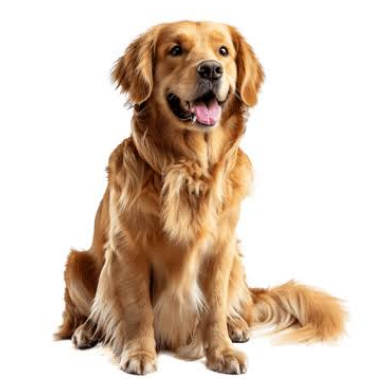

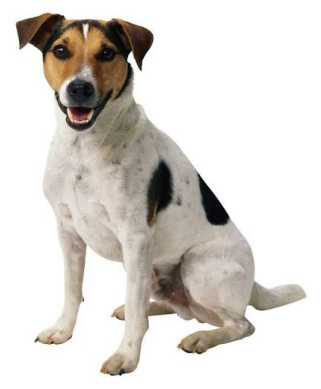

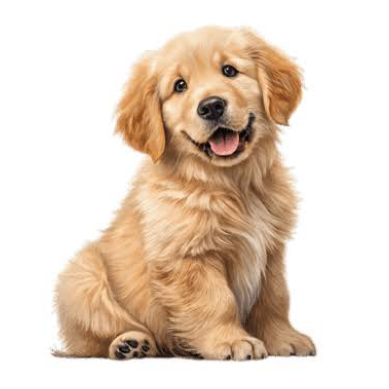

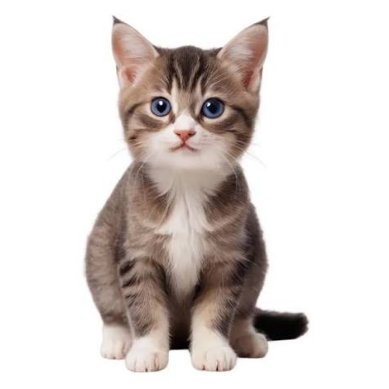

In [24]:
from matplotlib import pyplot as plt

query_text = "dog"
res = collection.query(
    query_texts=[query_text],
    n_results=4,
    include=["distances", "documents", "metadatas", "data"],
)
for img in res['data'][0]:
    plt.imshow(img)
    plt.axis('off')
    plt.show()
    print()